# NHS A&E | M01 and M02 evidence collection
**ICA2 · Intelligent Decision Support Systems**

This notebook archives the completed inventory and ingestion outputs, rather than processing the raw files again. It does not change `data/raw`, `data/staging` or the original reports. Each run creates two new timestamped evidence folders. Input fingerprints represent the files at collection time, not proof of the earlier execution. The source is the [project repository](https://github.com/neoscar10/NHS-A-E-IDSS) and [NHS England A&E publication series](https://www.england.nhs.uk/statistics/statistical-work-areas/ae-waiting-times-and-activity/).

## 1. Setup
Open the notebook in the cloned repository in VS Code, choose the project Python kernel and run all cells. M01/M02 must have completed first.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

repo_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "src/utils/evidence_exporter.py").is_file()), None)
if repo_root is None:
    raise FileNotFoundError("Open the cloned NHS-A-E-IDSS folder in VS Code.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
from src.utils.evidence_exporter import EvidenceRun, record_common_inputs, M01_REPORTS, M02_REPORTS
RUN_TESTS = True


## 2. M01: source inventory and historical coverage
**Question:** Is the intended monthly time window represented by the source files?

Read the saved inventory, check the number of source files, and record the source-format exceptions. The chart measures file coverage, not patient demand.

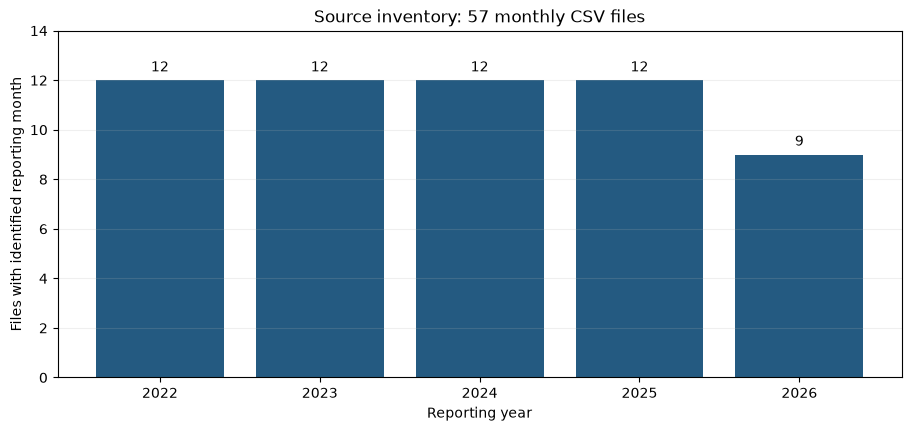

**Observed:** 57 files; 57 distinct reporting months; 0 missing months; 0 files requiring review; 1 source-format warnings.

**Decision:** Retain the original source files and review documented format warnings; use the staged data for detailed validation.

WindowsPath('C:/Users/hp/NHS-A-E-IDSS/docs/evidence/M01_Data_Inventory/20261117T231656Z_0395ca30/reports/inventory_interpretation.md')

In [2]:
m01 = EvidenceRun(repo_root, "M01", "Archive completed source inventory and visualise saved coverage.")
record_common_inputs(m01)
for path in M01_REPORTS:
    m01.copy_report(path)
manifest = pd.read_csv(m01.path / "reports/source_manifest.csv", dtype=str, keep_default_na=False)
coverage = json.loads((m01.path / "reports/m01_coverage.json").read_text(encoding="utf-8"))
assert len(manifest) == coverage["source_files"], "Source inventory and coverage counts disagree."
counts = manifest.loc[manifest["content_month"].ne(""), "content_month"].str[:4].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
bars = ax.bar(counts.index, counts.values, color="#245A81")
ax.bar_label(bars, padding=4)
ax.set(title=f"Source inventory: {len(manifest)} monthly CSV files",
       xlabel="Reporting year", ylabel="Files with identified reporting month", ylim=(0, max(12, counts.max()) + 2))
ax.grid(axis="y", alpha=.2)
m01.save_figure(fig, "01_source_coverage.png")
plt.show()
review_m01 = bool(coverage["missing_months"] or coverage["duplicate_months"] or coverage["unexpected_months"] or coverage["preliminary_review_files"])
text = (f"**Observed:** {coverage['source_files']} files; {coverage['unique_content_months']} distinct reporting months; "
        f"{len(coverage['missing_months'])} missing months; {coverage['preliminary_review_files']} files requiring review; "
        f"{coverage.get('source_format_warning_files', 0)} source-format warnings.\n\n"
        "**Decision:** " + ("Investigate before accepting ingestion." if review_m01 else "Retain the original source files and review documented format warnings; use the staged data for detailed validation."))
display(Markdown(text))
m01.write_text("reports/inventory_interpretation.md", text)


## 3. M02: ingestion counts and provenance
**Question:** Did ingestion retain the original provider and national aggregate rows?

Compare saved M01 and M02 counts. National totals remain in the staged dataset and will be separated at M04. The combined file is fingerprinted, not copied.

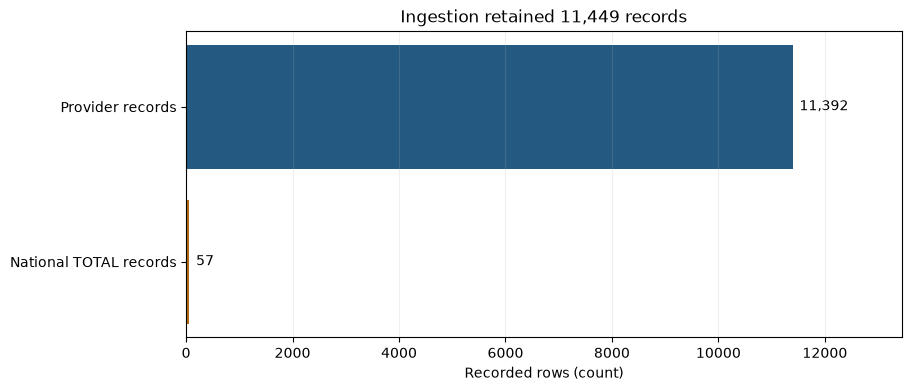

**Observed:** 11,392 provider rows and 57 national totals. 22 source fields plus 4 provenance fields.

**Count comparison:** Saved inventory and ingestion counts agree.

**Decision:** Retain the staged data unchanged; validate all numerical measures and provider-month keys at M03.

WindowsPath('C:/Users/hp/NHS-A-E-IDSS/docs/evidence/M02_Data_Ingestion/20261117T231657Z_ab53b016/reports/ingestion_interpretation.md')

In [3]:
m02 = EvidenceRun(repo_root, "M02", "Archive completed ingestion summary and visualise retained record groups.")
record_common_inputs(m02, include_staged=True)
for path in M02_REPORTS:
    m02.copy_report(path)
summary = json.loads((m02.path / "reports/m02_ingestion_summary.json").read_text(encoding="utf-8"))
provider, aggregate = summary["provider_rows"], summary["national_total_rows_retained"]
review_m02 = (summary["combined_rows_including_totals"] != coverage["total_csv_data_rows"] or
              provider != coverage["total_provider_rows"] or aggregate != coverage["total_aggregate_rows"] or
              provider + aggregate != summary["combined_rows_including_totals"])
counts = pd.Series({"Provider records": provider, "National TOTAL records": aggregate})
fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
bars = ax.barh(counts.index, counts.values, color=["#245A81", "#B56B13"])
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{x:,}" for x in counts], padding=5)
ax.set(title=f"Ingestion retained {summary['combined_rows_including_totals']:,} records",
       xlabel="Recorded rows (count)", xlim=(0, max(1, counts.max()) * 1.18))
ax.grid(axis="x", alpha=.2)
m02.save_figure(fig, "01_ingested_record_groups.png")
plt.show()
text = (f"**Observed:** {provider:,} provider rows and {aggregate:,} national totals. "
        f"{summary['original_source_columns']} source fields plus {summary['additive_provenance_columns']} provenance fields.\n\n"
        "**Count comparison:** " + ("Review required." if review_m02 else "Saved inventory and ingestion counts agree.") +
        "\n\n**Decision:** Retain the staged data unchanged; validate all numerical measures and provider-month keys at M03.")
display(Markdown(text))
m02.write_text("reports/ingestion_interpretation.md", text)


## 4. Fresh regression tests and evidence manifests
These tests verify code behaviour on synthetic fixtures, not the historical NHS outcomes. The output logs are dated now. A saved notebook can be retained separately by pressing Ctrl+S after execution.

In [4]:
if RUN_TESTS:
    for run in (m01, m02):
        rc = run.run_tests("tests/test_m01_m02.py")
        print(run.milestone, "pytest exit code:", rc)
for run, review in ((m01, review_m01), (m02, review_m02)):
    path = run.finish("Existing reports preserved byte-for-byte. Charts use saved report values. Tests, if enabled, are fresh synthetic-fixture tests.", review)
    print(run.milestone, path.relative_to(repo_root))
    print(json.loads((path / "evidence_manifest.json").read_text(encoding="utf-8"))["status"])


M01 pytest exit code: 0
M02 pytest exit code: 0
M01 docs\evidence\M01_Data_Inventory\20261117T231656Z_0395ca30
COMPLETE
M02 docs\evidence\M02_Data_Ingestion\20261117T231657Z_ab53b016
COMPLETE
